In [1]:
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.patches import Patch

from helper import get_amino_acid_sequence, summarise_activations
from interplm.embedders import ESM
from interplm.sae.inference import load_sae_from_hf

/opt/anaconda3/envs/interpreting-plms/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# I used GPT-6.1 Sol High Effort to find proteins from varied biological contexts
# to support my learning alongside analysis using SAEs.

# Testing layer-4 SAE feature 8893 on a fixed membrane-protein panel

**Hypothesis:** feature 8893 responds preferentially to membrane-spanning regions. This panel tests whether the pattern seen in CD2 and phospholamban generalizes across different membrane proteins and biological settings, including proteins with multiple membrane crossings.

**Selection recorded: 19 November 2026.** The 12 proteins below were chosen using biological role, membrane topology and practical sequence length. Their reviewed UniProt entries and annotated transmembrane regions were checked before adding this cell. None was selected from a feature-8893 ranking or a previously tested positive example. Keep the full panel, including weak or zero responses, when you run the analysis.

There are **five single-pass and seven multipass proteins**, covering animal, bacterial, plant, fungal and viral settings. All have helical transmembrane annotations; this panel tests that membrane architecture. Canonical sequences are **97–760 amino acids** long, keeping the initial experiment manageable with whole sequences.

## Single-pass proteins

| Protein / UniProt | Biological setting and role | Length (aa) | Annotated membrane-spanning segment |
|---|---|---:|---|
| **Transferrin receptor 1 (TFRC)** — [P02786](https://www.uniprot.org/uniprotkb/P02786/entry#subcellular_location) | Human cell surface/endosomes — brings transferrin-bound iron into cells. | 760 | 68–88 |
| **CD8 alpha (CD8A)** — [P01732](https://www.uniprot.org/uniprotkb/P01732/entry#subcellular_location) | Human T-cell surface — co-receptor involved in recognizing antigen presented by MHC class I. | 235 | 183–203 |
| **Synaptobrevin-2 (VAMP2)** — [P63027](https://www.uniprot.org/uniprotkb/P63027/entry#subcellular_location) | Human synaptic vesicles — a SNARE that helps vesicles fuse with the presynaptic membrane during neurotransmitter release. | 116 | 95–114 |
| **Cell division protein FtsL** — [P0AEN4](https://www.uniprot.org/uniprotkb/P0AEN4/entry#subcellular_location) | Escherichia coli K-12 inner membrane — helps coordinate the machinery that divides a bacterial cell. | 121 | 35–57 |
| **Influenza A matrix protein 2 (M2)** — [P06821](https://www.uniprot.org/uniprotkb/P06821/entry#subcellular_location) | Influenza A/Puerto Rico/8/1934 (H1N1), viral/host membranes — a proton channel involved in viral uncoating. | 97 | 23–43 |

## Multipass proteins

| Protein / UniProt | Biological setting and role | Length (aa) | Membrane passes per chain |
|---|---|---:|---:|
| **Aquaporin-1 (AQP1)** — [P29972](https://www.uniprot.org/uniprotkb/P29972/entry#subcellular_location) | Human plasma membrane — a water channel involved in water balance. | 269 | 6 |
| **Rhodopsin** — [P08100](https://www.uniprot.org/uniprotkb/P08100/entry#subcellular_location) | Human rod photoreceptor membranes — a light-sensitive receptor for vision in dim light. | 348 | 7 |
| **Lactose permease (LacY)** — [P02920](https://www.uniprot.org/uniprotkb/P02920/entry#subcellular_location) | Escherichia coli K-12 inner membrane — imports sugars such as lactose together with protons. | 417 | 12 |
| **Multidrug transporter EmrE** — [P23895](https://www.uniprot.org/uniprotkb/P23895/entry#subcellular_location) | Escherichia coli K-12 inner membrane — exports toxic compounds using the proton gradient. | 110 | 4 |
| **Uncoupling protein 1 (UCP1)** — [P25874](https://www.uniprot.org/uniprotkb/P25874/entry#subcellular_location) | Human brown-fat mitochondrial inner membrane — dissipates the proton gradient to generate heat. | 307 | 6 |
| **Photosystem II protein D1 (PsbA)** — [P83755](https://www.uniprot.org/uniprotkb/P83755/entry#subcellular_location) | Arabidopsis thaliana chloroplast thylakoid membrane — part of the light-driven reaction center involved in water oxidation and electron transfer. | 353 | 5 |
| **Protein transport protein Sec61** — [P32915](https://www.uniprot.org/uniprotkb/P32915/entry#subcellular_location) | Saccharomyces cerevisiae S288c endoplasmic reticulum — part of the channel that imports proteins into the ER and inserts membrane proteins. | 480 | 10 |

**Topology notes.** Pass counts describe one polypeptide chain, not the number of subunits in a channel or complex. CD8A is a type-I single-pass protein, TFRC and FtsL are type-II, M2 is type-III, and VAMP2 has a C-terminal membrane anchor (UniProt type IV). For CD8A, use the canonical membrane-bound sequence; its alternative secreted isoform is outside this panel. AQP1 has six full transmembrane helices plus two separately annotated intramembrane regions (69–82 and 187–199); keep these partial membrane insertions distinct when marking the sequence.

**Intramembrane** - a section of the protein that sits within the membrane without crossing all the way through it.

For aquaporin-1 (AQP1):
- Transmembrane regions cross from one side of the membrane to the other.
- Intramembrane regions dip partway into the membrane, then turn back toward the same side.

## Reference membrane boundaries and evidence

Positions below are **1-based, inclusive, and refer to the canonical UniProt sequence**, including any signal peptide. Signal-peptide annotations are not counted as additional stable membrane passes. Boundaries, evidence codes and entry versions were read from UniProt on **19 November 2026**. Entry links above show the biological context; JSON links below expose the exact feature fields. Evidence strength varies between proteins and between topology claims and exact boundary assignments.

<details>
<summary>Show all transmembrane intervals, evidence links and UniProt entry versions</summary>

| UniProt accession | Transmembrane intervals | Evidence attached to these transmembrane features | Entry / sequence version |
|---|---|---|---|
| [P02786 JSON](https://rest.uniprot.org/uniprotkb/P02786.json) | 68–88 | [ECO:0000255](https://evidenceontology.org/term/ECO%3A0000255/); no source reference attached | 273 / 2 |
| [P01732 JSON](https://rest.uniprot.org/uniprotkb/P01732.json) | 183–203 | [ECO:0000255](https://evidenceontology.org/term/ECO%3A0000255/); no source reference attached | 241 / 1 |
| [P63027 JSON](https://rest.uniprot.org/uniprotkb/P63027.json) | 95–114 | [ECO:0000255](https://evidenceontology.org/term/ECO%3A0000255/); no source reference attached | 187 / 3 |
| [P0AEN4 JSON](https://rest.uniprot.org/uniprotkb/P0AEN4.json) | 35–57 | [ECO:0000255](https://evidenceontology.org/term/ECO%3A0000255/); [HAMAP MF_00910](https://hamap.expasy.org/rule/MF_00910) | 138 / 1 |
| [P06821 JSON](https://rest.uniprot.org/uniprotkb/P06821.json) | 23–43 | [ECO:0000255](https://evidenceontology.org/term/ECO%3A0000255/); [HAMAP MF_04069](https://hamap.expasy.org/rule/MF_04069) | 155 / 1 |
| [P29972 JSON](https://rest.uniprot.org/uniprotkb/P29972.json) | 12–29, 47–65, 91–109, 134–153, 164–181, 207–224 | [ECO:0000305](https://evidenceontology.org/term/ECO%3A0000305/); [PubMed 35835865](https://pubmed.ncbi.nlm.nih.gov/35835865/)<br>[ECO:0007744](https://evidenceontology.org/term/ECO%3A0007744/); [PDB 8CT2](https://www.rcsb.org/structure/8CT2) | 252 / 3 |
| [P08100 JSON](https://rest.uniprot.org/uniprotkb/P08100.json) | 37–61, 74–96, 111–133, 153–173, 203–224, 253–274, 285–309 | [ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed 26200343](https://pubmed.ncbi.nlm.nih.gov/26200343/)<br>[ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/); [PubMed 28753425](https://pubmed.ncbi.nlm.nih.gov/28753425/) | 250 / 1 |
| [P02920 JSON](https://rest.uniprot.org/uniprotkb/P02920.json) | 8–34, 42–70, 75–100, 105–129, 141–163, 167–186, 221–249, 254–278, 289–308, 312–334, 347–374, 378–398 | No evidence code/reference attached to the individual TM feature objects. The multipass topology statement separately cites [PubMed 2164211](https://pubmed.ncbi.nlm.nih.gov/2164211/) with [ECO:0000269](https://evidenceontology.org/term/ECO%3A0000269/). | 208 / 1 |
| [P23895 JSON](https://rest.uniprot.org/uniprotkb/P23895.json) | 4–21, 34–52, 58–80, 87–104 | [ECO:0000305](https://evidenceontology.org/term/ECO%3A0000305/); [PubMed 17005200](https://pubmed.ncbi.nlm.nih.gov/17005200/) | 188 / 1 |
| [P25874 JSON](https://rest.uniprot.org/uniprotkb/P25874.json) | 11–32, 74–96, 117–133, 179–195, 213–232, 267–289 | [ECO:0000255](https://evidenceontology.org/term/ECO%3A0000255/); no source reference attached | 202 / 3 |
| [P83755 JSON](https://rest.uniprot.org/uniprotkb/P83755.json) | 29–46, 118–133, 142–156, 197–218, 274–288 | [ECO:0000255](https://evidenceontology.org/term/ECO%3A0000255/); [HAMAP MF_01379](https://hamap.expasy.org/rule/MF_01379) | 162 / 2 |
| [P32915 JSON](https://rest.uniprot.org/uniprotkb/P32915.json) | 33–55, 76–95, 120–141, 147–167, 213–224, 241–260, 291–311, 362–381, 417–434, 438–459 | [ECO:0000305](https://evidenceontology.org/term/ECO%3A0000305/); no source reference attached | 208 / 1 |

ECO codes distinguish [sequence-model evidence (ECO:0000255)](https://evidenceontology.org/term/ECO%3A0000255/), [curator inference (ECO:0000305)](https://evidenceontology.org/term/ECO%3A0000305/), [experimental evidence (ECO:0000269)](https://evidenceontology.org/term/ECO%3A0000269/) and [combined computational/experimental evidence (ECO:0007744)](https://evidenceontology.org/term/ECO%3A0007744/); all four codes here refer to manual assertions. A reviewed entry does not imply that every membrane boundary was independently measured experimentally.

</details>

Check the reference coordinates against the entry version you download before plotting, since live UniProt annotations can change.

Compare activation **inside the annotated transmembrane regions with the rest of each sequence**, and inspect whether it covers one, several or all membrane crossings. A peak somewhere in a membrane protein alone is insufficient to identify a transmembrane-region feature. The earlier VASP, carbonic anhydrase II and calmodulin-1 sequences remain useful negative controls for broader specificity; they are not part of this membrane-only panel.

In [3]:
single_pass_amino_acid_dict = get_amino_acid_sequence([
    'P02786',  # Transferrin receptor 1 (TFRC)
    'P01732',  # CD8 alpha (CD8A)
    'P63027',  # Synaptobrevin-2 (VAMP2)
    'P0AEN4',  # Cell division protein FtsL
    'P06821',  # Influenza A matrix protein 2 (M2)
])

multipass_amino_acid_dict = get_amino_acid_sequence([
    'P29972',  # Aquaporin-1 (AQP1)
    'P08100',  # Rhodopsin
    'P02920',  # Lactose permease (LacY)
    'P23895',  # Multidrug transporter EmrE
    'P25874',  # Uncoupling protein 1 (UCP1)
    'P83755',  # Photosystem II protein D1 (PsbA)
    'P32915',  # Protein transport protein Sec61
])

In [4]:
display(single_pass_amino_acid_dict)
display(multipass_amino_acid_dict)

{'P02786': 'MMDQARSAFSNLFGGEPLSYTRFSLARQVDGDNSHVEMKLAVDEEENADNNTKANVTKPKRCSGSICYGTIAVIVFFLIGFMIGYLGYCKGVEPKTECERLAGTESPVREEPGEDFPAARRLYWDDLKRKLSEKLDSTDFTGTIKLLNENSYVPREAGSQKDENLALYVENQFREFKLSKVWRDQHFVKIQVKDSAQNSVIIVDKNGRLVYLVENPGGYVAYSKAATVTGKLVHANFGTKKDFEDLYTPVNGSIVIVRAGKITFAEKVANAESLNAIGVLIYMDQTKFPIVNAELSFFGHAHLGTGDPYTPGFPSFNHTQFPPSRSSGLPNIPVQTISRAAAEKLFGNMEGDCPSDWKTDSTCRMVTSESKNVKLTVSNVLKEIKILNIFGVIKGFVEPDHYVVVGAQRDAWGPGAAKSGVGTALLLKLAQMFSDMVLKDGFQPSRSIIFASWSAGDFGSVGATEWLEGYLSSLHLKAFTYINLDKAVLGTSNFKVSASPLLYTLIEKTMQNVKHPVTGQFLYQDSNWASKVEKLTLDNAAFPFLAYSGIPAVSFCFCEDTDYPYLGTTMDTYKELIERIPELNKVARAAAEVAGQFVIKLTHDVELNLDYERYNSQLLSFVRDLNQYRADIKEMGLSLQWLYSARGDFFRATSRLTTDFGNAEKTDRFVMKKLNDRVMRVEYHFLSPYVSPKESPFRHVFWGSGSHTLPALLENLKLRKQNNGAFNETLFRNQLALATWTIQGAANALSGDVWDIDNEF',
 'P01732': 'MALPVTALLLPLALLLHAARPSQFRVSPLDRTWNLGETVELKCQVLLSNPTSGCSWLFQPRGAAASPTFLLYLSQNKPKAAEGLDTQRFSGKRLGDTFVLTLSDFRRENEGYYFCSALSNSIMYFSHFVPVFLPAKPTTTPAPRPPTPAPTIASQPLSLRPEACRPAAGGAVHTRGLDFACDIYIWAPLAGTCGVLLLSLVITLYCNHRNRRR

{'P29972': 'MASEFKKKLFWRAVVAEFLATTLFVFISIGSALGFKYPVGNNQTAVQDNVKVSLAFGLSIATLAQSVGHISGAHLNPAVTLGLLLSCQISIFRALMYIIAQCVGAIVATAILSGITSSLTGNSLGRNDLADGVNSGQGLGIEIIGTLQLVLCVLATTDRRRRDLGGSAPLAIGLSVALGHLLAIDYTGCGINPARSFGSAVITHNFSNHWIFWVGPFIGGALAVLIYDFILAPRSSDLTDRVKVWTSGQVEEYDLDADDINSRVEMKPK',
 'P08100': 'MNGTEGPNFYVPFSNATGVVRSPFEYPQYYLAEPWQFSMLAAYMFLLIVLGFPINFLTLYVTVQHKKLRTPLNYILLNLAVADLFMVLGGFTSTLYTSLHGYFVFGPTGCNLEGFFATLGGEIALWSLVVLAIERYVVVCKPMSNFRFGENHAIMGVAFTWVMALACAAPPLAGWSRYIPEGLQCSCGIDYYTLKPEVNNESFVIYMFVVHFTIPMIIIFFCYGQLVFTVKEAAAQQQESATTQKAEKEVTRMVIIMVIAFLICWVPYASVAFYIFTHQGSNFGPIFMTIPAFFAKSAAIYNPVIYIMMNKQFRNCMLTTICCGKNPLGDDEASATVSKTETSQVAPA',
 'P02920': 'MYYLKNTNFWMFGLFFFFYFFIMGAYFPFFPIWLHDINHISKSDTGIIFAAISLFSLLFQPLFGLLSDKLGLRKYLLWIITGMLVMFAPFFIFIFGPLLQYNILVGSIVGGIYLGFCFNAGAPAVEAFIEKVSRRSNFEFGRARMFGCVGWALCASIVGIMFTINNQFVFWLGSGCALILAVLLFFAKTDAPSSATVANAVGANHSAFSLKLALELFRQPKLWFLSLYVIGVSCTYDVFDQQFANFFTSFFATGEQGTRVFGYVTTMGELLNASIMFFAPLIINRIGGKNALLLAGTIMSVRIIGSSFATSALEVVILKTLHMFEVPFLLVGCFKYITSQF

In [5]:
# Single-pass protein sequences.
P02786_sequence = single_pass_amino_acid_dict['P02786']
P01732_sequence = single_pass_amino_acid_dict['P01732']
P63027_sequence = single_pass_amino_acid_dict['P63027']
P0AEN4_sequence = single_pass_amino_acid_dict['P0AEN4']
P06821_sequence = single_pass_amino_acid_dict['P06821']

# Multipass protein sequences.
P29972_sequence = multipass_amino_acid_dict['P29972']
P08100_sequence = multipass_amino_acid_dict['P08100']
P02920_sequence = multipass_amino_acid_dict['P02920']
P23895_sequence = multipass_amino_acid_dict['P23895']
P25874_sequence = multipass_amino_acid_dict['P25874']
P83755_sequence = multipass_amino_acid_dict['P83755']
P32915_sequence = multipass_amino_acid_dict['P32915']

# Combine both groups for the shared analysis.
amino_acid_dict = single_pass_amino_acid_dict | multipass_amino_acid_dict

In [6]:
layer = 4
feature_id = 8893

esm_model = ESM(
    model_name="facebook/esm2_t6_8M_UR50D",
    device="cpu",
)

In [7]:
# Run every sequence through the same loaded model at layer 4.
embeddings_by_protein = {
    accession: esm_model.embed_single_sequence(sequence, layer=layer)
    for accession, sequence in amino_acid_dict.items()
}

# Each residue has a 320-dimensional embedding.
for accession, embeddings in embeddings_by_protein.items():
    assert isinstance(embeddings, np.ndarray), f"{accession}: expected a NumPy array."
    expected_shape = (len(amino_acid_dict[accession]), 320)
    assert embeddings.shape == expected_shape, (
        f"{accession}: expected shape {expected_shape}, got {embeddings.shape}."
    )

In [8]:
# Load the pretrained SAE and switch to evaluation mode.
sae = load_sae_from_hf(
    plm_model="esm2-8m",
    plm_layer=layer,
)
sae = sae.to("cpu").eval()

Loading configs from /Users/ishanmitra/.cache/huggingface/hub/models--Elana--InterPLM-esm2-8m/snapshots/81d2429cd9dae7175f1dcd8b4c649a20cdc06c8c/layer_4/config.yaml
Loaded data type: <class 'interplm.train.configs.TrainingRunConfig'>
Data keys: Not a dict


In [9]:
# Reuse the loaded SAE to calculate every feature for each protein.
activations_by_protein = {}
with torch.inference_mode():
    for accession, embeddings in embeddings_by_protein.items():
        activations_by_protein[accession] = sae.encode_feat_subset(
            torch.as_tensor(embeddings, dtype=torch.float32),
            list(range(sae.dict_size)),
            normalize_features=True,
        ).cpu().numpy()

# One row per residue and one column per SAE feature.
for accession, activations in activations_by_protein.items():
    assert isinstance(activations, np.ndarray), f"{accession}: expected a NumPy array."
    expected_shape = (len(amino_acid_dict[accession]), sae.dict_size)
    assert activations.shape == expected_shape, (
        f"{accession}: expected shape {expected_shape}, got {activations.shape}."
    )

In [10]:
# Bind the data once so calls need only the accession and feature ID.
summarise_protein_activations = partial(
    summarise_activations,
    amino_acid_dict=amino_acid_dict,
    activations_by_protein=activations_by_protein,
)

In [11]:
# Print a feature summary for each protein.
for accession in amino_acid_dict:
    summarise_protein_activations(accession, feature_id=feature_id)
    print()

P02786 — feature 8893; activation statistics ×100 (not percentages)
            Count   Mean     Q1  Median     Q3
Amino acid                                    
A              60 0.2920 0.0000  0.0000 0.0000
C               8 2.2305 0.0000  0.0000 3.1921
D              43 0.0183 0.0000  0.0000 0.0000
E              46 0.0000 0.0000  0.0000 0.0000
F              46 1.3138 0.0000  0.0000 0.0000
G              53 0.4636 0.0000  0.0000 0.0000
H              13 0.0000 0.0000  0.0000 0.0000
I              32 2.5250 0.0000  0.0000 0.0000
K              50 0.2788 0.0000  0.0000 0.0000
L              71 0.4272 0.0000  0.0000 0.0000
M              14 0.6721 0.0000  0.0000 0.0000
N              42 0.0856 0.0000  0.0000 0.0000
P              31 0.1368 0.0000  0.0000 0.0000
Q              23 0.0000 0.0000  0.0000 0.0000
R              33 0.1637 0.0000  0.0000 0.0000
S              56 0.2346 0.0000  0.0000 0.0000
T              44 0.5139 0.0000  0.0000 0.0000
V              56 0.7638 0.0000  0.0000

In [12]:
membrane_protein_names = {
    'P02786': 'Transferrin receptor 1 (TFRC)',
    'P01732': 'CD8 alpha (CD8A)',
    'P63027': 'Synaptobrevin-2 (VAMP2)',
    'P0AEN4': 'Cell division protein FtsL',
    'P06821': 'Influenza A matrix protein 2 (M2)',
    'P29972': 'Aquaporin-1 (AQP1)',
    'P08100': 'Rhodopsin',
    'P02920': 'Lactose permease (LacY)',
    'P23895': 'Multidrug transporter EmrE',
    'P25874': 'Uncoupling protein 1 (UCP1)',
    'P83755': 'Photosystem II protein D1 (PsbA)',
    'P32915': 'Protein transport protein Sec61',
}

# Full membrane crossings from the topology notes (1-based, inclusive).
transmembrane_regions = {
    'P02786': [(68, 88)],
    'P01732': [(183, 203)],
    'P63027': [(95, 114)],
    'P0AEN4': [(35, 57)],
    'P06821': [(23, 43)],
    'P29972': [(12, 29), (47, 65), (91, 109), (134, 153), (164, 181), (207, 224)],
    'P08100': [(37, 61), (74, 96), (111, 133), (153, 173), (203, 224), (253, 274), (285, 309)],
    'P02920': [(8, 34), (42, 70), (75, 100), (105, 129), (141, 163), (167, 186),
               (221, 249), (254, 278), (289, 308), (312, 334), (347, 374), (378, 398)],
    'P23895': [(4, 21), (34, 52), (58, 80), (87, 104)],
    'P25874': [(11, 32), (74, 96), (117, 133), (179, 195), (213, 232), (267, 289)],
    'P83755': [(29, 46), (118, 133), (142, 156), (197, 218), (274, 288)],
    'P32915': [(33, 55), (76, 95), (120, 141), (147, 167), (213, 224),
               (241, 260), (291, 311), (362, 381), (417, 434), (438, 459)],
}

In [13]:
overlap_rows = []
for accession, protein_name in membrane_protein_names.items():
    sequence = amino_acid_dict[accession]
    values = activations_by_protein[accession][:, feature_id].astype(np.float64)
    total = values.sum()
    regions = transmembrane_regions[accession]
    membrane_mask = np.zeros(len(sequence), dtype=bool)
    for start, end in regions:
        membrane_mask[start - 1:end] = True  # 1-based inclusive -> NumPy slice
    active = values > 0
    active_inside = membrane_mask & active

    overlap_rows.append({
        'Accession': accession,
        'Protein': protein_name,
        'Peak activation': values.max(),
        'Peak position': int(values.argmax() + 1) if total > 0 else None,
        'Nonzero residues': int(np.count_nonzero(active)),
        'Annotated membrane regions': ', '.join(f'{start}–{end}' for start, end in regions),
        'Activation inside membrane (%)': (
            100 * values[membrane_mask].sum() / total if total > 0 else np.nan
        ),
        'Active residues inside membrane': int(np.count_nonzero(active_inside)),
        'Active residues outside membrane': int(np.count_nonzero(~membrane_mask & active)),
        'Distinct amino acids active inside membrane': len(
            set(np.array(list(sequence))[active_inside])
        ),
    })

feature_8893_overlap = pd.DataFrame(overlap_rows).set_index('Accession')
display(feature_8893_overlap.style.format({
    'Peak activation': '{:.6f}',
    'Peak position': '{:.0f}',
    'Activation inside membrane (%)': '{:.2f}',
    'Active residues inside membrane': '{:.0f}',
    'Active residues outside membrane': '{:.0f}',
    'Distinct amino acids active inside membrane': '{:.0f}',
}, na_rep='—'))

,Protein,Peak activation,Peak position,Nonzero residues,Annotated membrane regions,Activation inside membrane (%),Active residues inside membrane,Active residues outside membrane,Distinct amino acids active inside membrane
Accession,,,,,,,,,
P02786,Transferrin receptor 1 (TFRC),0.276743,75,44,68–88,74.76,18,26,9
P01732,CD8 alpha (CD8A),0.774843,197,50,183–203,79.55,21,29,11
P63027,Synaptobrevin-2 (VAMP2),0.462625,106,22,95–114,92.53,18,4,7
P0AEN4,Cell division protein FtsL,0.012595,47,1,35–57,100.00,1,0,1
P06821,Influenza A matrix protein 2 (M2),0.404102,36,43,23–43,82.80,21,22,10
P29972,Aquaporin-1 (AQP1),0.066603,222,17,"12–29, 47–65, 91–109, 134–153, 164–181, 207–224",61.87,9,8,5
P08100,Rhodopsin,0.153243,214,92,"37–61, 74–96, 111–133, 153–173, 203–224, 253–274, 285–309",75.33,65,27,14
P02920,Lactose permease (LacY),0.000000,—,0,"8–34, 42–70, 75–100, 105–129, 141–163, 167–186, 221–249, 254–278, 289–308, 312–334, 347–374, 378–398",—,0,0,0
P23895,Multidrug transporter EmrE,0.031706,108,9,"4–21, 34–52, 58–80, 87–104",72.23,7,2,5


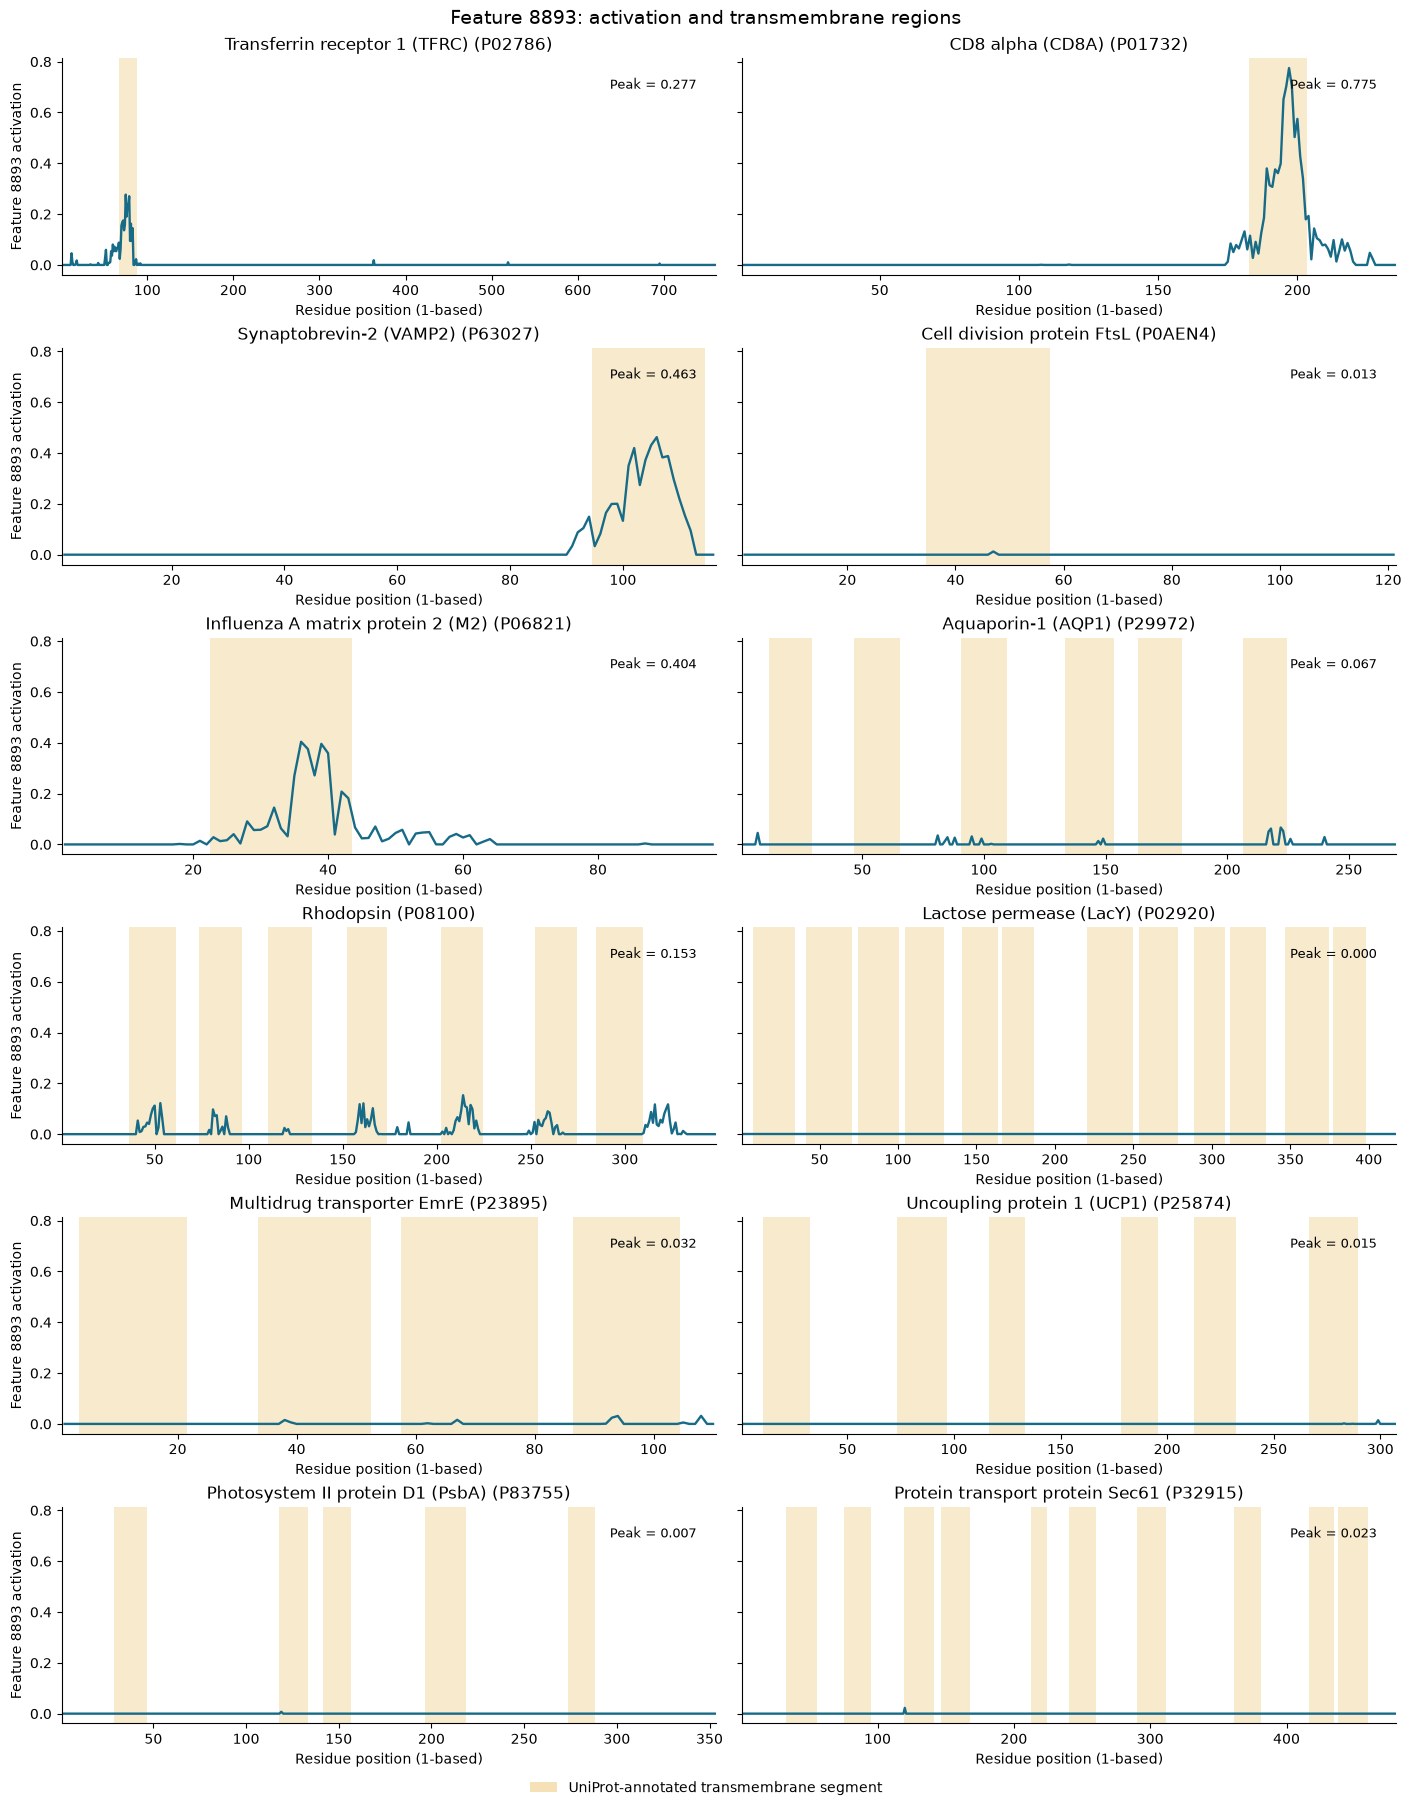

In [14]:
# Plot all proteins with their annotated transmembrane regions.
n_rows = (len(membrane_protein_names) + 1) // 2
fig, axes = plt.subplots(
    n_rows, 2, figsize=(14, 3 * n_rows), sharey=True, layout='constrained',
)

for ax, (accession, protein_name) in zip(axes.flat, membrane_protein_names.items()):
    sequence = amino_acid_dict[accession]
    values = activations_by_protein[accession][:, feature_id]
    ax.plot(np.arange(1, len(sequence) + 1), values, color='#176b87', lw=1.7)
    for start, end in transmembrane_regions[accession]:
        ax.axvspan(start - 0.5, end + 0.5, color='#e9b44c', alpha=0.28, lw=0)
    ax.set(
        title=f'{protein_name} ({accession})',
        xlim=(0.5, len(sequence) + 0.5),
        xlabel='Residue position (1-based)',
    )
    ax.text(
        0.97, 0.91, f'Peak = {values.max():.3f}',
        ha='right', va='top', transform=ax.transAxes, fontsize=9,
    )
    ax.spines[['top', 'right']].set_visible(False)

for ax in axes[:, 0]:
    ax.set_ylabel(f'Feature {feature_id} activation')

fig.suptitle(f'Feature {feature_id}: activation and transmembrane regions', fontsize=14)
fig.legend(
    handles=[Patch(
        facecolor='#e9b44c', alpha=0.4, label='UniProt-annotated transmembrane segment',
    )],
    loc='outside lower center', frameon=False,
)
plt.show()

In [17]:
aqp1_values = activations_by_protein['P29972'][:, feature_id].astype(np.float64)
aqp1_total = aqp1_values.sum()
aqp1_regions = transmembrane_regions['P29972']

for label, regions in (
    ('Transmembrane only', aqp1_regions),
    ('Transmembrane + intramembrane', aqp1_regions + [(69, 82), (187, 199)]),
):
    aqp1_mask = np.zeros(len(aqp1_values), dtype=bool)
    for start, end in regions:
        aqp1_mask[start - 1:end] = True
    percentage = (
        100 * aqp1_values[aqp1_mask].sum() / aqp1_total if aqp1_total > 0 else np.nan
    )
    print(f'{label}: {percentage:.2f}%')

Transmembrane only: 61.87%
Transmembrane + intramembrane: 68.59%


It appears the hypothesis is mostly supported, with some exceptions?

Here we can see that for Aquaporin-1 (AQP1) has 61.87% of its feature activation inside the transmembrane region, which is borderline/alright.

Uncoupling protein 1 (UCP1) is the only one that completely goes against the grain, with 15.07% inside the region.

Lactose permease (LacY) has no activations at all (it's total is 0).

So it appears that Feature 8893 shows a membrane-associated activation in several proteins, but its response varies substantially between proteins, which suggests sensitivity to a more specific sequence or structural context.
(we explore this next)

Note that in the paper ([InterPLM](https://arxiv.org/abs/2412.12101) by Elana Simon and James Zou), **Section 3.3 - Sparse Autoencoder Features Capture More Biological Annotations than Neuron**, it is outlined that learned SAE features can be much more specific than many concept annotations. So which is why feature 8893 potentially identifying something more specific than a transmembrane region, remains a valid hypothesis.

First we should try and investigate what distinguishes strongly activating membrane segments from weak/silent segments.

We have a few other things we can explore next:

- Does the feature identify hydrophobic stretches in particular?
- prefers specific amino acids/short motifs?
- recognises a particular part of a membrane helix?
- depends on the surrounding context (neighbouring residues)?